# Using Python libraries with ScalaPy

[ScalaPy](https://scalapy.dev) runs a CPython interpreter inside the JVM, and lets Scala code call Python code, and
the other way around. From a notebook, it gives access to the whole Python ecosystem, like
[NumPy](https://numpy.org), [pandas](https://pandas.pydata.org) or [Matplotlib](https://matplotlib.org) here.

This notebook needs a Python installation with these packages, and the shared library of Python (`libpython3.x.so`).
The Docker image of this repository has both. If you run it on your own machine, install them with
```bash
pip install numpy pandas matplotlib
```
in the Python environment whose `python3` comes first in the `PATH` of the kernel.

## Setup

Besides ScalaPy itself, we load
- [python-native-libs](https://github.com/kiendang/python-native-libs), which finds the shared library of the
  `python3` from the `PATH`, and the settings ScalaPy needs to use it,
- *almond-scalapy*, which shows Python objects in notebooks the way Jupyter does for Python, like pandas data frames
  as HTML tables.

In [1]:
import $ivy.`dev.scalapy::scalapy-core:0.5.3`
import $ivy.`ai.kien::python-native-libs:0.2.4`
import $ivy.`sh.almond::almond-scalapy:0.15.0`

import $ivy.$
import $ivy.$
import $ivy.$

ScalaPy relies on [JNA](https://github.com/java-native-access/jna) to call Python. Almond lists JNA among its own
dependencies but doesn't ship it, so `import $ivy` skips it, and we add it to the class path ourselves.

In [2]:
import scala.jdk.CollectionConverters._

interp.load.cp(
  coursierapi.Fetch.create()
    .addDependencies(coursierapi.Dependency.of("net.java.dev.jna", "jna", "5.11.0"))
    .fetch()
    .asScala
    .map(os.Path(_))
    .toSeq
)

import scala.jdk.CollectionConverters._

ScalaPy reads its settings from Java properties, when it starts Python. So we set them before running any Python code.

In [3]:
import ai.kien.python.Python

Python().scalapyProperties.get.foreach {
  case (key, value) => System.setProperty(key, value)
}

import ai.kien.python.Python

In [4]:
import me.shadaj.scalapy.py
import me.shadaj.scalapy.py.{PyQuote, SeqConverters}

almond.scalapy.initDisplay

import me.shadaj.scalapy.py
import me.shadaj.scalapy.py.{PyQuote, SeqConverters}

## Calling Python

`py.Dynamic.global` gives access to the Python built-ins. Its members are untyped (`py.Dynamic`): any method call
compiles, and is checked by Python when it runs. Scala values, like numbers or strings, are converted to Python ones
when passed to Python, and `as` converts Python values back to Scala.

In [5]:
val pyLen = py.Dynamic.global.len("Hello from Scala")
pyLen.as[Int]

pyLen: py.Dynamic = 16
res5_1: Int = 16

In [6]:
py.Dynamic.global.sum(py.Dynamic.global.range(1, 101)).as[Int]

res6: Int = 5050

Scala collections can be passed to Python either as a copy (`toPythonCopy`), or as a proxy that reads the Scala
collection (`toPythonProxy`), which avoids copying large collections. Named arguments are passed as-is to Python.

In [7]:
val fruits = Seq("banana", "Apple", "cherry")
py.Dynamic.global.sorted(fruits.toPythonCopy, key = py.Dynamic.global.str.lower)

fruits: Seq[String] = List("banana", "Apple", "cherry")
res7_1: py.Dynamic = ['Apple', 'banana', 'cherry']

Scala functions can be passed to Python, which calls them like Python functions:

In [8]:
val tenTimes: Int => Int = n => n * 10
py.Dynamic.global.list(py.Dynamic.global.map(tenTimes, Seq(1, 2, 3).toPythonProxy)).as[Seq[Int]]

tenTimes: Int => Int = ammonite.$sess.cmd8$Helper$$Lambda$3571/0x00007ca1f4a563b8@7977bf7a
res8_1: Seq[Int] = List(10, 20, 30)

Python code can also be evaluated directly, with `py.eval` for expressions, `py.exec` for statements, or the `py`
string interpolator, which passes Scala values to the Python expression.

In [9]:
py.exec("""
def fib(n):
    a, b = 0, 1
    for _ in range(n):
        a, b = b, a + b
    return a
""")

py.Dynamic.global.fib(80).as[Long]

res9_1: Long = 23416728348467685L

In [10]:
val factor = 7
py"[$factor * i for i in range(5)]"

factor: Int = 7
res10_1: py.Dynamic = [0, 7, 14, 21, 28]

Python exceptions are thrown as `py.PythonException` on the Scala side.

In [11]:
try py.eval("1 / 0").toString
catch {
  case e: py.PythonException => e.getMessage.linesIterator.toSeq.last
}

res11: String = "<class 'ZeroDivisionError'> division by zero"

## Typed facades

To get static types and completions, describe Python objects with *facades*: traits or objects annotated
with `@py.native`, whose members are implemented by Python (`py.native`).
Here, a facade for the [`fractions.Fraction`](https://docs.python.org/3/library/fractions.html) class:

In [12]:
@py.native trait Fraction extends py.Object {
  def numerator: Long = py.native
  def denominator: Long = py.native
  def limit_denominator(max_denominator: Int): Fraction = py.native
}

val fractions = py.module("fractions")
val pi = fractions.Fraction(math.Pi).as[Fraction]

defined trait Fraction
fractions: py.Module = <module 'fractions' from '/opt/conda/lib/python3.11/fractions.py'>
pi: Fraction = 884279719003555/281474976710656

In [13]:
val approx = pi.limit_denominator(1000)
(approx.numerator, approx.denominator)

approx: Fraction = 355/113
res13_1: (Long, Long) = (355L, 113L)

Modules can get facades too, by extending `py.StaticModule`:

In [14]:
@py.native object Statistics extends py.StaticModule("statistics") {
  def mean(data: py.Any): Double = py.native
  def stdev(data: py.Any): Double = py.native
}

val measures = Seq(2.5, 3.1, 2.8, 3.6, 2.9)
(Statistics.mean(measures.toPythonProxy), Statistics.stdev(measures.toPythonProxy))

defined object Statistics
measures: Seq[Double] = List(2.5, 3.1, 2.8, 3.6, 2.9)
res14_2: (Double, Double) = (2.98, 0.40865633483405106)

## NumPy

Arithmetic operators on `py.Dynamic` values call the Python ones, so NumPy arrays can be combined like in Python.
`bracketAccess` corresponds to Python's `[]`.

In [15]:
val np = py.module("numpy")
np.set_printoptions(threshold = 20) // keeps the outputs of large arrays short

val matrix = np.arange(12).reshape(3, 4)

np: py.Module = <module 'numpy' from '/opt/conda/lib/python3.11/site-packages/numpy/__init__.py'>
res15_1: py.Dynamic = None
matrix: py.Dynamic = [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

In [16]:
(matrix * 2 + 1).bracketAccess(1)

res16: py.Dynamic = [ 9 11 13 15]

In [17]:
val rng = np.random.default_rng(42)
val samples = rng.normal(loc = 10, scale = 2, size = 10000)
(np.mean(samples).as[Double], np.std(samples).as[Double])

rng: py.Dynamic = Generator(PCG64)
samples: py.Dynamic = [10.60943416  7.92003179 11.50090239 ... 10.17049754 12.2494884
  9.63430021]
res17_2: (Double, Double) = (9.979500249171975, 2.012571537074082)

## pandas

Thanks to *almond-scalapy*, pandas data frames are shown as HTML tables.

In [18]:
val pd = py.module("pandas")

val cities = pd.DataFrame(py.Dynamic.global.dict(
  city = Seq("Paris", "Marseille", "Lyon", "Toulouse", "Nice").toPythonCopy,
  population = Seq(2102650, 873076, 522250, 504078, 348085).toPythonCopy,
  area = Seq(105.4, 240.6, 47.87, 118.3, 71.92).toPythonCopy
))

,city,population,area
0,Paris,2102650,105.40
1,Marseille,873076,240.60
2,Lyon,522250,47.87
3,Toulouse,504078,118.30
4,Nice,348085,71.92


pd: py.Module = <module 'pandas' from '/opt/conda/lib/python3.11/site-packages/pandas/__init__.py'>

In [19]:
cities
  .assign(density = cities.bracketAccess("population") / cities.bracketAccess("area"))
  .sort_values("density", ascending = false)
  .round(1)

,city,population,area,density
0,Paris,2102650,105.4,19949.2
2,Lyon,522250,47.9,10909.8
4,Nice,348085,71.9,4839.9
3,Toulouse,504078,118.3,4261.0
1,Marseille,873076,240.6,3628.7


In [20]:
cities.describe()

,population,area
count,5.000000e+00,5.000000
mean,8.700278e+05,116.818000
std,7.153076e+05,74.538929
min,3.480850e+05,47.870000
25%,5.040780e+05,71.920000
50%,5.222500e+05,105.400000
75%,8.730760e+05,118.300000
max,2.102650e+06,240.600000


## Matplotlib

Matplotlib figures can be rendered to SVG, and shown with almond's `Svg`.

In [21]:
val plt = py.module("matplotlib.pyplot")

def show(fig: py.Dynamic): almond.display.Svg = {
  val svg = py.module("io").StringIO()
  fig.savefig(svg, format = "svg")
  plt.close(fig)
  almond.display.Svg(svg.getvalue().as[String])
}

plt: py.Module = <module 'matplotlib.pyplot' from '/opt/conda/lib/python3.11/site-packages/matplotlib/pyplot.py'>
defined function show

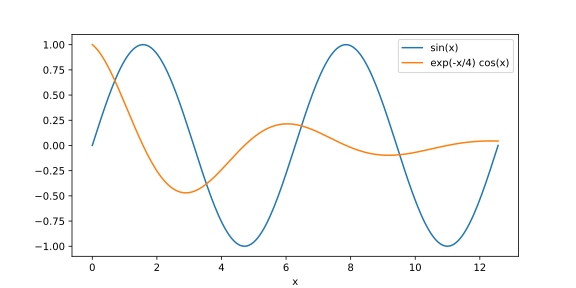

fig: py.Dynamic = Figure(800x400)
ax: py.Dynamic = Axes(0.125,0.11;0.775x0.77)
x: py.Dynamic = [ 0.          0.06314759  0.12629518 ... 12.44007543 12.50322302
 12.56637061]
res22_3: py.Dynamic = [<matplotlib.lines.Line2D object at 0x7ca0d2e9ed90>]
res22_4: py.Dynamic = [<matplotlib.lines.Line2D object at 0x7ca0d2c19850>]
res22_5: py.Dynamic = Text(0.5, 10.679999999999996, 'x')
res22_6: py.Dynamic = Legend

In [22]:
val fig = plt.figure(figsize = (8, 4))
val ax = fig.add_subplot()

val x = np.linspace(0, 4 * math.Pi, 200)
ax.plot(x, np.sin(x), label = "sin(x)")
ax.plot(x, np.exp(-x / 4) * np.cos(x), label = "exp(-x/4) cos(x)")
ax.set_xlabel("x")
ax.legend()

show(fig)